In [1]:
# Install the packages this notebook needs.
# If they are already installed, this step is quick and harmless.
%pip install -q pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


# 02. Freedom and money: GDP per capita

## Words first

GDP per capita means the total value of goods and services
produced in a country in a year, divided by the number of people
in that country. It is a rough measure of average economic output
per person. It is not income in a person's pocket, and it says
nothing about how that output is shared.

The source here is the World Bank, indicator NY.GDP.PCAP.CD,
GDP per capita in current US dollars. Current dollars means the
figures are not adjusted for inflation in this notebook. That is
fine for a single year comparison, which is what this notebook
does first.

## Correlation, in plain words

Correlation is a number from minus 1 to plus 1. It says whether
two things tend to go up together. A value near plus 1 means when
one is high, the other tends to be high too. A value near 0 means
no clear straight line pattern. A value near minus 1 means when
one is high, the other tends to be low.

Correlation is not causation. A strong correlation does not prove
that freedom causes higher GDP, or that higher GDP causes
freedom. Both could be shaped by other things, like history,
institutions, geography, or education. This notebook reports the
correlation and stops there. It does not claim a cause.

In [2]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (10, 6)
ROOT = pathlib.Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
print('Data folder:', DATA)
print('Charts folder:', CHARTS)

Data folder: /home/hatch/workspace/repo-builds/human-freedom-index/data/processed
Charts folder: /home/hatch/workspace/repo-builds/human-freedom-index/charts


In [3]:
merged = pd.read_csv(DATA / 'freedom_merged.csv')
latest = merged[merged['year'] == 2016].dropna(subset=['gdp_per_capita_usd'])
print('Countries with both a freedom score and GDP per capita in 2016:', len(latest))
print('Pearson correlation, overall freedom versus GDP per capita:',
      round(latest['hf_score'].corr(latest['gdp_per_capita_usd']), 3))
print('Spearman correlation, overall freedom versus GDP per capita:',
      round(latest['hf_score'].corr(latest['gdp_per_capita_usd'], method='spearman'), 3))
print('Spearman is used too, because GDP per capita is very skewed: a few')
print('countries have very high values, and Spearman uses ranks, not dollars.')

Countries with both a freedom score and GDP per capita in 2016: 161
Pearson correlation, overall freedom versus GDP per capita: 0.618


Spearman correlation, overall freedom versus GDP per capita: 0.689
Spearman is used too, because GDP per capita is very skewed: a few
countries have very high values, and Spearman uses ranks, not dollars.


## The scatter: freedom on one axis, GDP per capita on the other

Each dot is a country in 2016. The horizontal axis uses a log
scale. A log scale spreads out the low end and squeezes the high
end, so countries with very different GDP levels can all be seen.
Without it, most dots would pile up on the left.

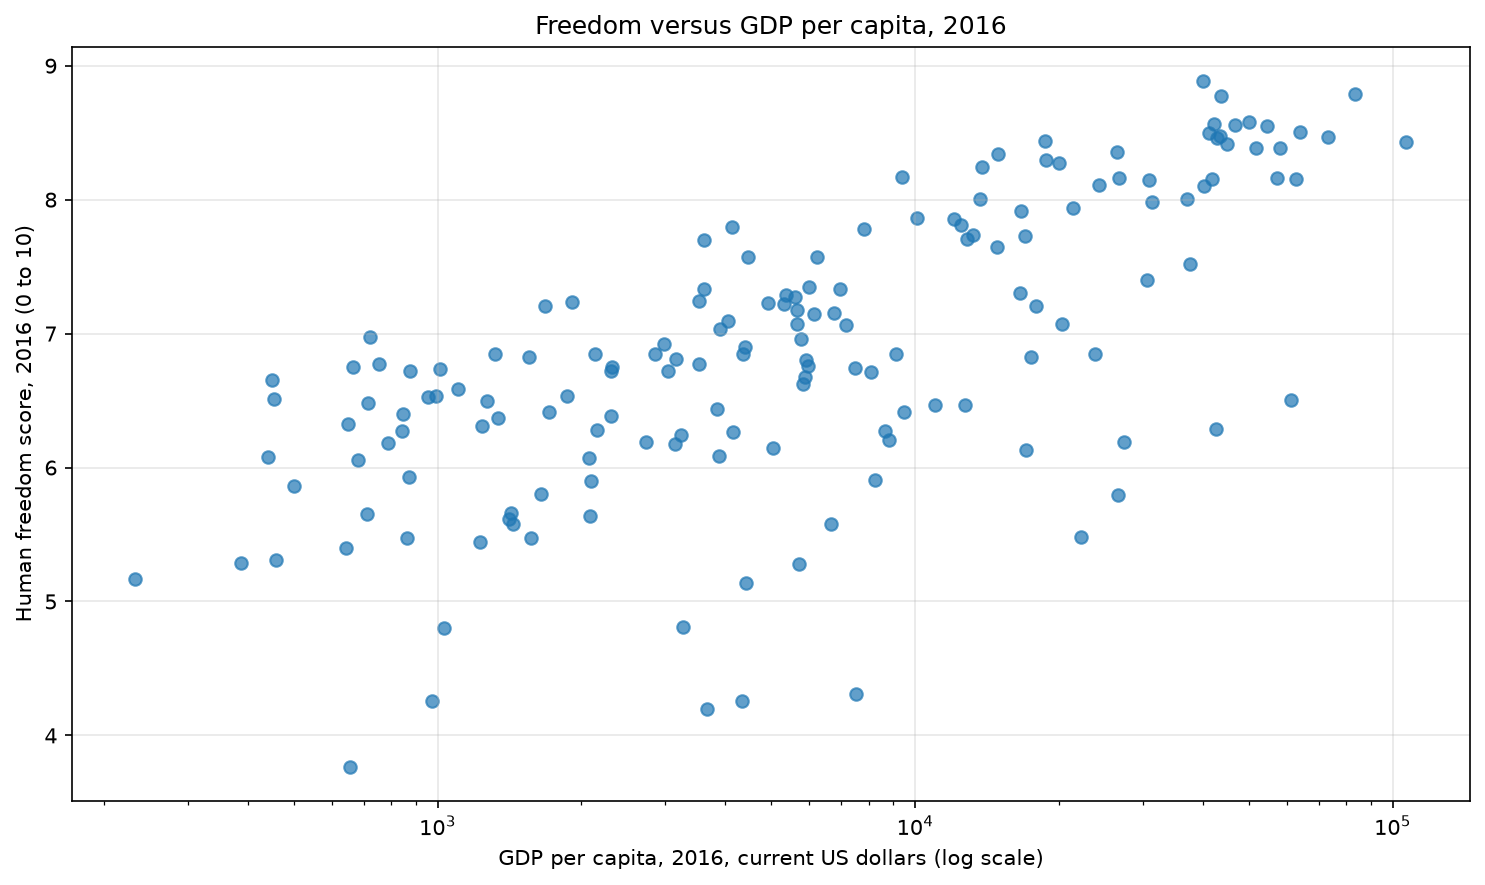

In [4]:
fig, ax = plt.subplots()
ax.scatter(latest['gdp_per_capita_usd'], latest['hf_score'], alpha=0.7)
ax.set_xscale('log')
ax.set_xlabel('GDP per capita, 2016, current US dollars (log scale)')
ax.set_ylabel('Human freedom score, 2016 (0 to 10)')
ax.set_title('Freedom versus GDP per capita, 2016')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_freedom_vs_gdp.png')
plt.show()

## The same pattern, grouped

Grouping helps when a scatter is crowded. Here, countries are
split into four equal groups by freedom score, from lowest to
highest. The chart shows the median GDP per capita in each group.
Median means the middle value, so one very rich country does not
pull the whole group up the way an average would.

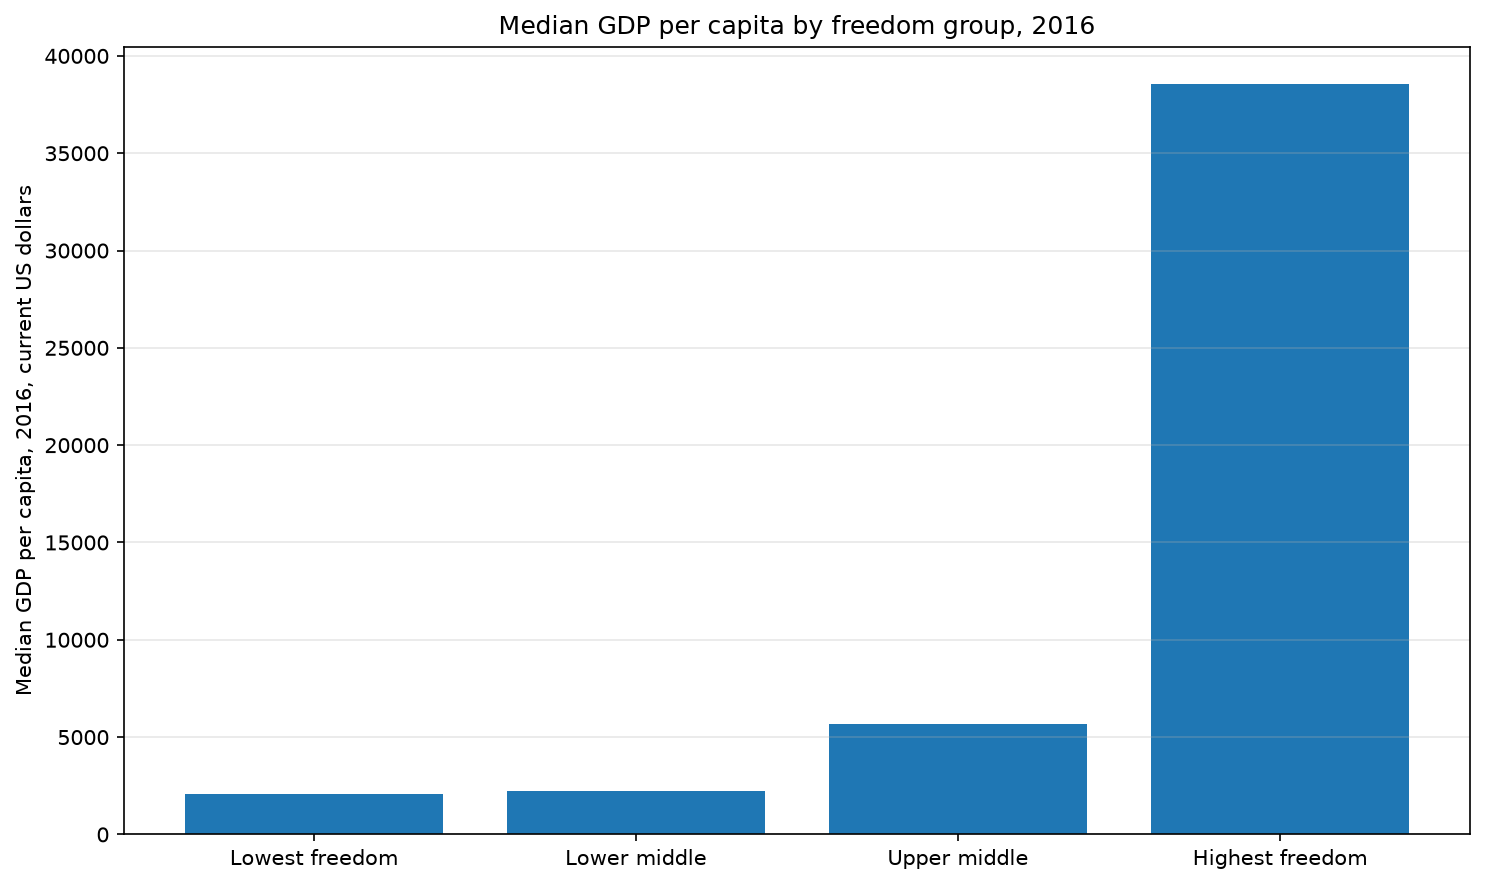

freedom_group
Lowest freedom      2070.0
Lower middle        2231.0
Upper middle        5648.0
Highest freedom    38556.0

Counts per group:
freedom_group
Lowest freedom     41
Lower middle       40
Upper middle       40
Highest freedom    40


In [5]:
latest = latest.copy()
latest['freedom_group'] = pd.qcut(latest['hf_score'], 4,
                                  labels=['Lowest freedom', 'Lower middle',
                                          'Upper middle', 'Highest freedom'])
grouped = latest.groupby('freedom_group', observed=True)['gdp_per_capita_usd'].median()
fig, ax = plt.subplots()
ax.bar(grouped.index, grouped.values)
ax.set_ylabel('Median GDP per capita, 2016, current US dollars')
ax.set_title('Median GDP per capita by freedom group, 2016')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_gdp_by_quartile.png')
plt.show()
print(grouped.round(0).to_string())
print()
print('Counts per group:')
print(latest['freedom_group'].value_counts().sort_index().to_string())

## What to take away, and what not to claim

In 2016, higher freedom scores go together with higher GDP per
capita in this dataset. That is a correlation, not proof of a
cause. It could run in either direction, or both could reflect
other factors. The honest sentence is: countries with higher
freedom scores in 2016 tended to have higher GDP per capita in
2016. Nothing more is claimed here.